<a href="https://colab.research.google.com/github/clobos/Biologia_2026/blob/main/semana12_TH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dados e estatísticas descritivas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

alpha = 0.05
controle = np.array([   4.17, 5.58, 5.18, 6.11, 4.50, 4.61, 5.17, 4.53, 5.33, 5.14])
tratamento1 = np.array([   4.81, 4.17, 4.41, 3.59, 5.87, 3.83, 6.03, 4.89, 4.32, 4.69])

grupos = {
    "Controle":     controle,
    "Tratamento 1": tratamento1
}
resumo = pd.DataFrame({
    nome: {
        "n":             x.size,
        "média":         x.mean(),
        "desvio-padrão": x.std(ddof=1),
        "variância":     x.var(ddof=1)
    }
    for nome, x in grupos.items()
}).T
print(resumo.round(4))

                 n  média  desvio-padrão  variância
Controle      10.0  5.032         0.5831     0.3400
Tratamento 1  10.0  4.661         0.7937     0.6299


# Normalidade para uma amostra

W = 0.9567 | valor-p = 0.7475 | Não rejeitar H0


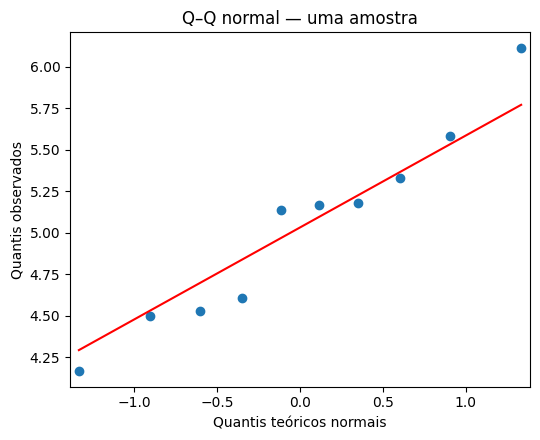

In [6]:
# Uma amostra: avaliar normalidade de x
amostra = controle   # vetor numérico com n observações

# 1) Teste de Shapiro–Wilk
W, p = stats.shapiro(amostra)
decisao = "Rejeitar H0" if p <= alpha else "Não rejeitar H0"
print(f"W = {W:.4f} | valor-p = {p:.4f} | {decisao}")

# 2) Gráfico Q–Q normal
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sm.qqplot(amostra, dist=stats.norm, line="s", ax=ax)
ax.set_title("Q–Q normal — uma amostra")
ax.set_xlabel("Quantis teóricos normais")
ax.set_ylabel("Quantis observados")
plt.tight_layout()
plt.show()

# Shapiro–Wilk por grupo

In [2]:
resultados = []
for nome, x in grupos.items():
    W, p = stats.shapiro(x)
    decisao = (
        "Rejeitar H0"
        if p <= alpha
        else "Não rejeitar H0"
    )
    resultados.append({
        "grupo":    nome,
        "n":        x.size,
        "W":        W,
        "valor-p":  p,
        "decisão":  decisao
    })
resultado_shapiro = pd.DataFrame(resultados)
print(resultado_shapiro.round(4))

          grupo   n       W  valor-p          decisão
0      Controle  10  0.9567   0.7475  Não rejeitar H0
1  Tratamento 1  10  0.9304   0.4519  Não rejeitar H0


# Gráficos Q–Q dos dois grupos

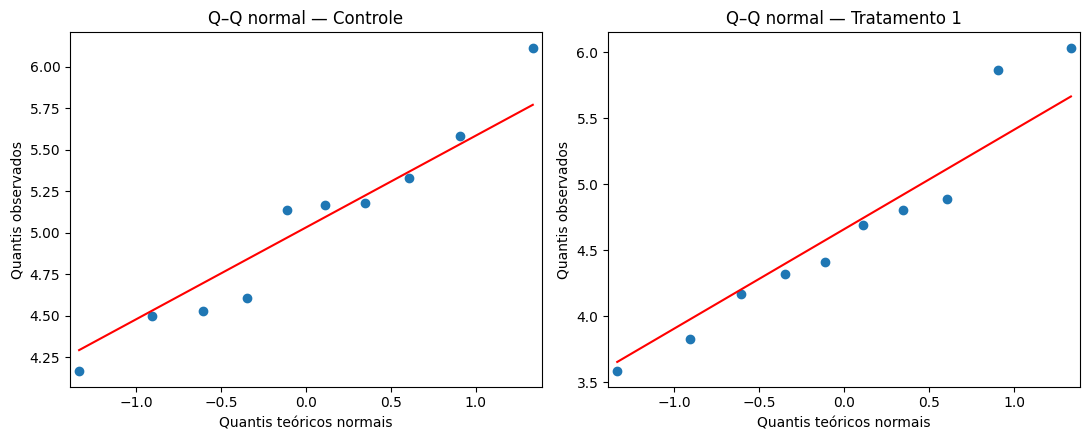

In [3]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (nome, x) in zip(eixos, grupos.items()):
    sm.qqplot(x, dist=stats.norm, line="s", ax=ax)
    ax.set_title(f"Q–Q normal — {nome}")
    ax.set_xlabel("Quantis teóricos normais")
    ax.set_ylabel("Quantis observados")

plt.tight_layout()
plt.show()

# Normalidade para duas amostras dependentes (pareadas)

W = 0.8874 | valor-p = 0.1583 | Não rejeitar H0


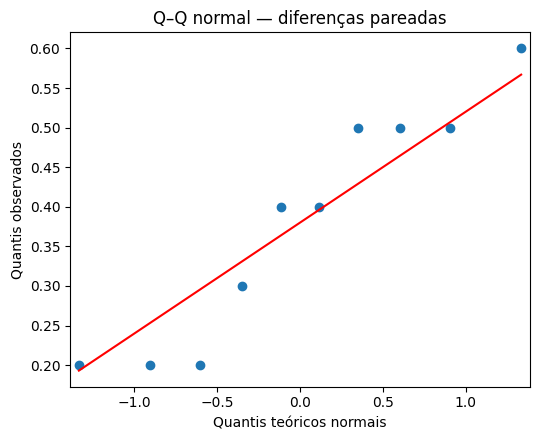

In [7]:
# Amostras pareadas: o mesmo indivíduo medido antes e depois
# (dados ilustrativos — substituir pelos dados reais)
antes  = np.array([5.1, 4.8, 6.0, 5.5, 4.9, 5.7, 5.2, 6.1, 5.0, 5.4])
depois = np.array([5.6, 5.0, 6.4, 5.9, 5.1, 6.3, 5.5, 6.6, 5.2, 5.9])

# A normalidade é avaliada na DIFERENÇA entre os pares
diferencas = depois - antes

# 1) Teste de Shapiro–Wilk nas diferenças
W, p = stats.shapiro(diferencas)
decisao = "Rejeitar H0" if p <= alpha else "Não rejeitar H0"
print(f"W = {W:.4f} | valor-p = {p:.4f} | {decisao}")

# 2) Gráfico Q–Q normal das diferenças
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sm.qqplot(diferencas, dist=stats.norm, line="s", ax=ax)
ax.set_title("Q–Q normal — diferenças pareadas")
ax.set_xlabel("Quantis teóricos normais")
ax.set_ylabel("Quantis observados")
plt.tight_layout()
plt.show()

# Teste F bilateral

In [4]:
s2_controle   = np.var(controle,    ddof=1)
s2_tratamento = np.var(tratamento1, ddof=1)

F_obs = s2_controle / s2_tratamento

gl1 = controle.size   - 1   # 9
gl2 = tratamento1.size - 1  # 9

cauda_esquerda = stats.f.cdf(F_obs, gl1, gl2)
cauda_direita  = stats.f.sf( F_obs, gl1, gl2)

p_F = min(1.0, 2 * min(cauda_esquerda, cauda_direita))

critico_inferior = stats.f.ppf(alpha / 2,       gl1, gl2)
critico_superior = stats.f.ppf(1 - alpha / 2,   gl1, gl2)

print(f"F observado:            {F_obs:.4f}")
print(f"Graus de liberdade:     ({gl1}, {gl2})")
print(f"Valor-p bilateral:      {p_F:.4f}")
print(f"Região de não rejeição: [{critico_inferior:.4f}, {critico_superior:.4f}]")
print("Rejeitar H0" if p_F <= alpha else "Não rejeitar H0")

F observado:            0.5397
Graus de liberdade:     (9, 9)
Valor-p bilateral:      0.3719
Região de não rejeição: [0.2484, 4.0260]
Não rejeitar H0


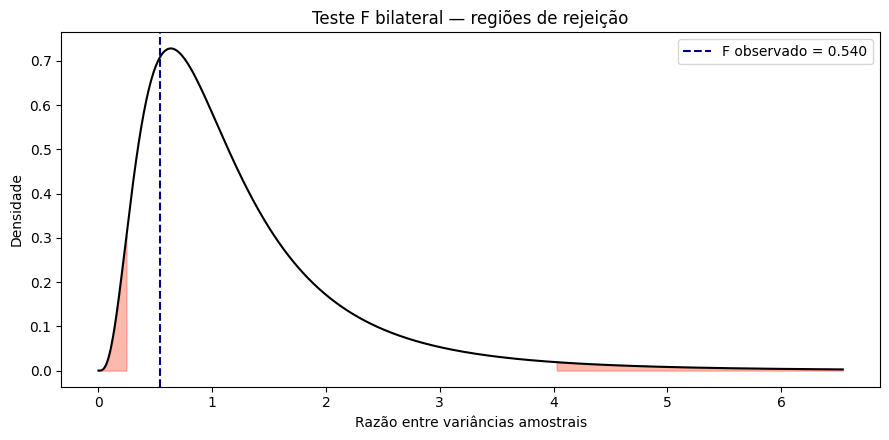

In [5]:
limite = max(stats.f.ppf(0.995, gl1, gl2), F_obs * 1.15)
x       = np.linspace(0.001, limite, 1200)
densidade = stats.f.pdf(x, gl1, gl2)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(x, densidade, color="black")

ax.fill_between(x, 0, densidade,
                where=(x <= critico_inferior),
                color="tomato", alpha=0.45)
ax.fill_between(x, 0, densidade,
                where=(x >= critico_superior),
                color="tomato", alpha=0.45)

ax.axvline(F_obs, color="navy", linestyle="--",
           label=f"F observado = {F_obs:.3f}")
ax.set_xlabel("Razão entre variâncias amostrais")
ax.set_ylabel("Densidade")
ax.set_title("Teste F bilateral — regiões de rejeição")
ax.legend()
plt.tight_layout()
plt.show()